In [16]:
# Import libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, roc_auc_score
from scipy import interp


In [17]:
df = pd.read_table('SMSSpamCollection.txt', 
                   sep='\t',
                   header=None,
                   names=['label', 'sms_message'])

df['label'] = df.label.map({'ham':0, 'spam':1})

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(df['sms_message'],
                                                    df['label'],
                                                    random_state=1)

# Instantiate CountVectorizer
count_vector = CountVectorizer()

# Fit training data
training_data = count_vector.fit_transform(X_train)

# Transform testing data
testing_data = count_vector.transform(X_test)

# Instantiate models
naive_bayes = MultinomialNB()
bag_mod = BaggingClassifier(n_estimators=200)
rf_mod = RandomForestClassifier(n_estimators=200)
ada_mod = AdaBoostClassifier(n_estimators=300, learning_rate=0.2)
svm_mod = SVC()

#### Fit each model 

In [18]:
naive_bayes.fit(training_data, y_train)
bag_mod.fit(training_data, y_train)
rf_mod.fit(training_data, y_train)
ada_mod.fit(training_data, y_train)
svm_mod.fit(training_data, y_train)

SVC()

#### Make Predictions

In [19]:
preds_nb = naive_bayes.predict(testing_data)
preds_bag = bag_mod.predict(testing_data)
preds_rf = rf_mod.predict(testing_data)
preds_ada = ada_mod.predict(testing_data)
preds_svm = svm_mod.predict(testing_data)


#### Calculate accuracy
Accuracy is the total correct divided by the total to predict
* Total Correct / Total Predicted

In [20]:
def accuracy(actual, preds):
    '''
    INPUT
    preds - predictions as a numpy array or pandas series
    actual - actual values as a numpy array or pandas series
    
    OUTPUT
    returns accuracy as float
    '''
    
    return np.sum(preds == actual)/len(actual)

print(accuracy(y_test, preds_nb))
print(accuracy_score(y_test, preds_nb))
                                    

0.9885139985642498
0.9885139985642498


#### Calculate precision 
Precision is the true positives over the predicted positive values 


In [21]:
def precision(actual, preds):
    ''' 
    INPUT
    positives = 1 
    negatives = 0
    
    OUTPUT
    returns precision as float
    '''
    tp = len(np.intersect1d(np.where(preds==1), np.where(actual==1)))
    pred_pos = (preds==1).sum()
    return tp/(pred_pos)

print(precision(y_test, preds_nb))
print(precision_score(y_test, preds_nb))

0.9720670391061452
0.9720670391061452


#### Calculate recall
Recall is true positives over all actual positive values

In [22]:
def recall(actual, preds):
    tp = len(np.intersect1d(np.where(preds==1), np.where(actual==1)))
    act_pos = (actual==1).sum()
    return tp/act_pos

print(recall(y_test, preds_nb))
print(recall_score(y_test, preds_nb))


0.9405405405405406
0.9405405405405406


#### Calculate F1 Score
F1 Score is:
* 2 * (precision*recall) / (precision+recall))

In [23]:
def f1(actual, preds):
    tp = len(np.intersect1d(np.where(preds==1), np.where(actual==1)))
    pred_pos = (preds==1).sum()
    prec = tp/(pred_pos)
    act_pos = (actual==1).sum()
    recall = tp/act_pos
    return 2*(prec*recall)/(prec+recall)

print(f1(y_test, preds_nb))
print(f1_score(y_test, preds_nb))
    

0.9560439560439562
0.9560439560439562


#### Fbeta Score

In [24]:
from sklearn.metrics import fbeta_score

print(fbeta_score(y_test, preds_bag, beta=1))
print(f1_score(y_test, preds_bag))

0.9021739130434783
0.9021739130434783


#### ROC Curve

0.9428539466618938


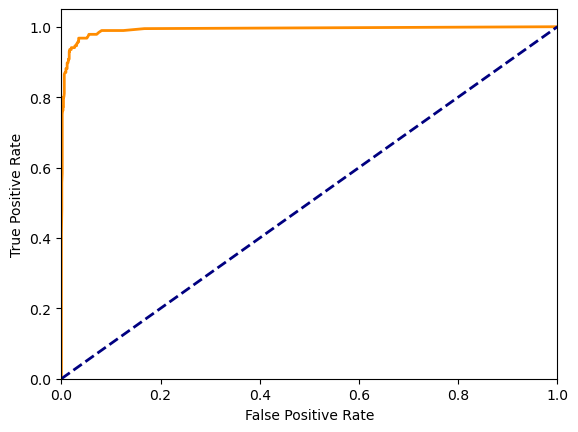

In [32]:
def build_roc_auc(model, X_train, X_test, y_train, y_test):
    y_preds = model.fit(X_train, y_train).predict_proba(X_test)
    # Compute ROC curve and ROC area
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    for i in range(len(y_test)):
        fpr[i], tpr[i], _ = roc_curve(y_test, y_preds[:, 1])
        roc_auc[i] = auc(fpr[i], tpr[i])
    
    # Compute micro-average ROC curve and ROC area
    fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_preds[:, 1].ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
    
    plt.plot(fpr[2], tpr[2], color='darkorange',
             lw=2, label='ROC Curve (area = %0.2f)' % roc_auc[2])
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.show
    
    return roc_auc_score(y_test, np.round(y_preds[:, 1]))

print(build_roc_auc(bag_mod, training_data, testing_data, y_train, y_test))
    
    

0.9682007338464294


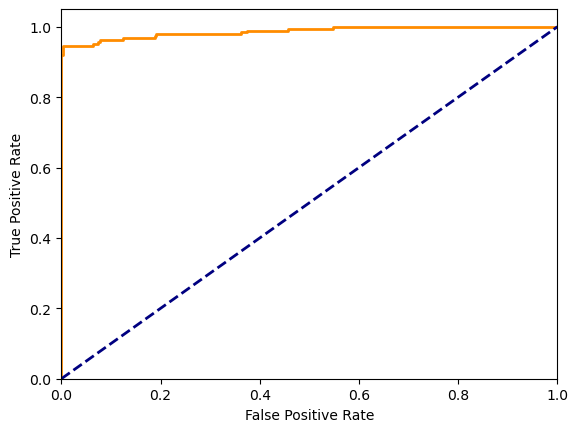

In [33]:
print(build_roc_auc(naive_bayes, training_data, testing_data, y_train, y_test))